# Progressive Visualization Benchmark Analysis

This notebook loads benchmark reports exported by `pink-lemonade-progressive-harness` and visualizes wire transfer, latency, request counts, cache reuse, and client memory across strategies and scenarios.

### Setup & regenerating results
Select the root `.venv` kernel (or launch JupyterLab with `./dev notebook`).

From the repository root, regenerate `benchmarks/results/latest.json`:
```bash
./dev benchmark --fast   # Light + Medium + MediumWhiteNoise
./dev benchmark          # + ConstrainedMobile, Heavy & HeavyWhiteNoise (10M, non-naive) + re-render
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# Resolve results/latest.json whether Jupyter is opened from repo root or benchmarks/.
CANDIDATES = [
    Path("results/latest.json"),
    Path("benchmarks/results/latest.json"),
]
REPORT_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
print(f"Loading {REPORT_PATH.resolve()}")

raw = json.loads(REPORT_PATH.read_text(encoding="utf-8"))
reports = raw["reports"]

workload_rows = []
step_rows = []

for rep in reports:
    scenario = rep["scenario_name"] or "custom"
    strategy = rep["strategy_name"]
    raw_bytes = max(rep["raw_points_bytes"], 1)
    budget_bytes = max(rep["memory_budget_bytes"], 1)

    for w in rep["workloads"]:
        tt = w["total_transport"]
        workload_rows.append(
            {
                "scenario": scenario,
                "strategy": strategy,
                "workload": w["name"],
                "points": rep["total_points"],
                "raw_kib": raw_bytes / 1024.0,
                "storage_kib": rep["storage_bytes"] / 1024.0,
                "storage_overhead_pct": 100.0 * (rep["storage_bytes"] - raw_bytes) / raw_bytes,
                "build_ms": rep["build_duration_ms"],
                "wire_kib": tt["total_wire_bytes"] / 1024.0,
                "completed_kib": tt["bytes_downloaded"] / 1024.0,
                "wasted_kib": tt["wasted_cancelled_bytes"] / 1024.0,
                "wire_pct_of_raw": 100.0 * tt["total_wire_bytes"] / raw_bytes,
                "requests": tt["completed_requests"],
                "cancelled": tt["cancelled_requests"],
                "mean_latency_ms": w["mean_latency_ms"],
                "peak_mem_kib": w["peak_client_memory_bytes"] / 1024.0,
                "budget_kib": budget_bytes / 1024.0,
                "network": rep["network"]["name"],
            }
        )

        cum_wire = w["open_transport"]["total_wire_bytes"]
        for idx, s in enumerate(w["steps"]):
            st = s["transport"]
            cum_wire += st["total_wire_bytes"]
            step_rows.append(
                {
                    "scenario": scenario,
                    "strategy": strategy,
                    "workload": w["name"],
                    "step_idx": idx,
                    "label": s["label"],
                    "view_min_x": s["view_min_x"],
                    "view_max_x": s["view_max_x"],
                    "view_width": s["view_width"],
                    "completed": s["completed"],
                    "latency_ms": s["latency_ms"],
                    "kernel_count": s["kernel_count"],
                    "wire_kib": st["total_wire_bytes"] / 1024.0,
                    "cum_wire_kib": cum_wire / 1024.0,
                    "wasted_kib": st["wasted_cancelled_bytes"] / 1024.0,
                    "requests": st["completed_requests"],
                    "cancelled": st["cancelled_requests"],
                    "client_mem_kib": s["client_memory_bytes"] / 1024.0,
                    "nmae_percent": s["nmae_percent"],
                }
            )

workloads_df = pd.DataFrame(workload_rows)
steps_df = pd.DataFrame(step_rows)
SCENARIOS = list(workloads_df["scenario"].unique())

print(
    f"Loaded {len(reports)} reports | scenarios={SCENARIOS} | "
    f"strategies={list(workloads_df['strategy'].unique())}"
)

Loading C:\projects\pink-lemonade\benchmarks\results\latest.json
Loaded 22 reports | scenarios=['light', 'medium', 'medium_white_noise', 'constrained_mobile', 'heavy', 'heavy_white_noise'] | strategies=['naive_full_download', 'paged_moment_tree', 'moment_kdtree', 'moment_ripmap']


## 1. Summary Scorecard & Improvement vs Baseline (`naive_full_download`)

In [2]:
display(
    workloads_df[
        [
            "scenario",
            "strategy",
            "workload",
            "wire_kib",
            "wire_pct_of_raw",
            "requests",
            "cancelled",
            "mean_latency_ms",
            "peak_mem_kib",
            "budget_kib",
        ]
    ].round(2)
)

# Side-by-side wire savings & latency speedup for scenarios that include naive_full_download
if "naive_full_download" in workloads_df["strategy"].values:
    base = workloads_df[workloads_df["strategy"] == "naive_full_download"][
        ["scenario", "workload", "wire_kib", "mean_latency_ms"]
    ].rename(columns={"wire_kib": "naive_wire_kib", "mean_latency_ms": "naive_latency_ms"})
    others = workloads_df[workloads_df["strategy"] != "naive_full_download"].merge(
        base, on=["scenario", "workload"], how="inner"
    )
    if not others.empty:
        others["wire_reduction_x"] = others["naive_wire_kib"] / others["wire_kib"].clip(lower=1e-9)
        others["latency_speedup_x"] = others["naive_latency_ms"] / others["mean_latency_ms"].clip(lower=1e-9)
        print("\nRelative improvement vs naive_full_download (higher is better):")
        display(
            others[
                [
                    "scenario",
                    "strategy",
                    "workload",
                    "wire_reduction_x",
                    "latency_speedup_x",
                    "storage_overhead_pct",
                ]
            ].round(2)
        )

,scenario,strategy,workload,wire_kib,wire_pct_of_raw,requests,cancelled,mean_latency_ms,peak_mem_kib,budget_kib
0,light,naive_full_download,cold_overview,234.38,100.00,2,0,69.00,234.38,1024.0
1,light,naive_full_download,progressive_zoom_in,234.38,100.00,2,0,11.50,234.38,1024.0
2,light,naive_full_download,lateral_pan,234.38,100.00,2,0,8.62,234.38,1024.0
3,light,naive_full_download,jump_and_revisit,234.38,100.00,2,0,11.50,234.38,1024.0
4,light,naive_full_download,rapid_interrupt_pan,234.38,100.00,2,5,69.00,234.38,1024.0
...,...,...,...,...,...,...,...,...,...,...
127,heavy_white_noise,moment_ripmap,progressive_zoom_in,4306.10,1.84,164,0,299.00,4457.33,16384.0
128,heavy_white_noise,moment_ripmap,lateral_pan,2934.10,1.25,118,0,256.75,3012.11,16384.0
129,heavy_white_noise,moment_ripmap,jump_and_revisit,3202.98,1.37,72,0,230.67,3259.20,16384.0
130,heavy_white_noise,moment_ripmap,rapid_interrupt_pan,820.10,0.35,18,5,307.00,858.59,16384.0



Relative improvement vs naive_full_download (higher is better):


,scenario,strategy,workload,wire_reduction_x,latency_speedup_x,storage_overhead_pct
0,light,paged_moment_tree,cold_overview,0.92,0.72,8.63
1,light,paged_moment_tree,progressive_zoom_in,0.92,0.72,8.63
2,light,paged_moment_tree,lateral_pan,4.89,0.18,8.63
3,light,paged_moment_tree,jump_and_revisit,3.98,0.27,8.63
4,light,paged_moment_tree,rapid_interrupt_pan,15.20,0.73,8.63
...,...,...,...,...,...,...
67,constrained_mobile,moment_ripmap,progressive_zoom_in,183.44,88.78,52.79
68,constrained_mobile,moment_ripmap,lateral_pan,191.87,57.20,52.79
69,constrained_mobile,moment_ripmap,jump_and_revisit,123.84,57.31,52.79
70,constrained_mobile,moment_ripmap,rapid_interrupt_pan,107.09,55.24,52.79


## 2. Workload Comparison (All Scenarios)

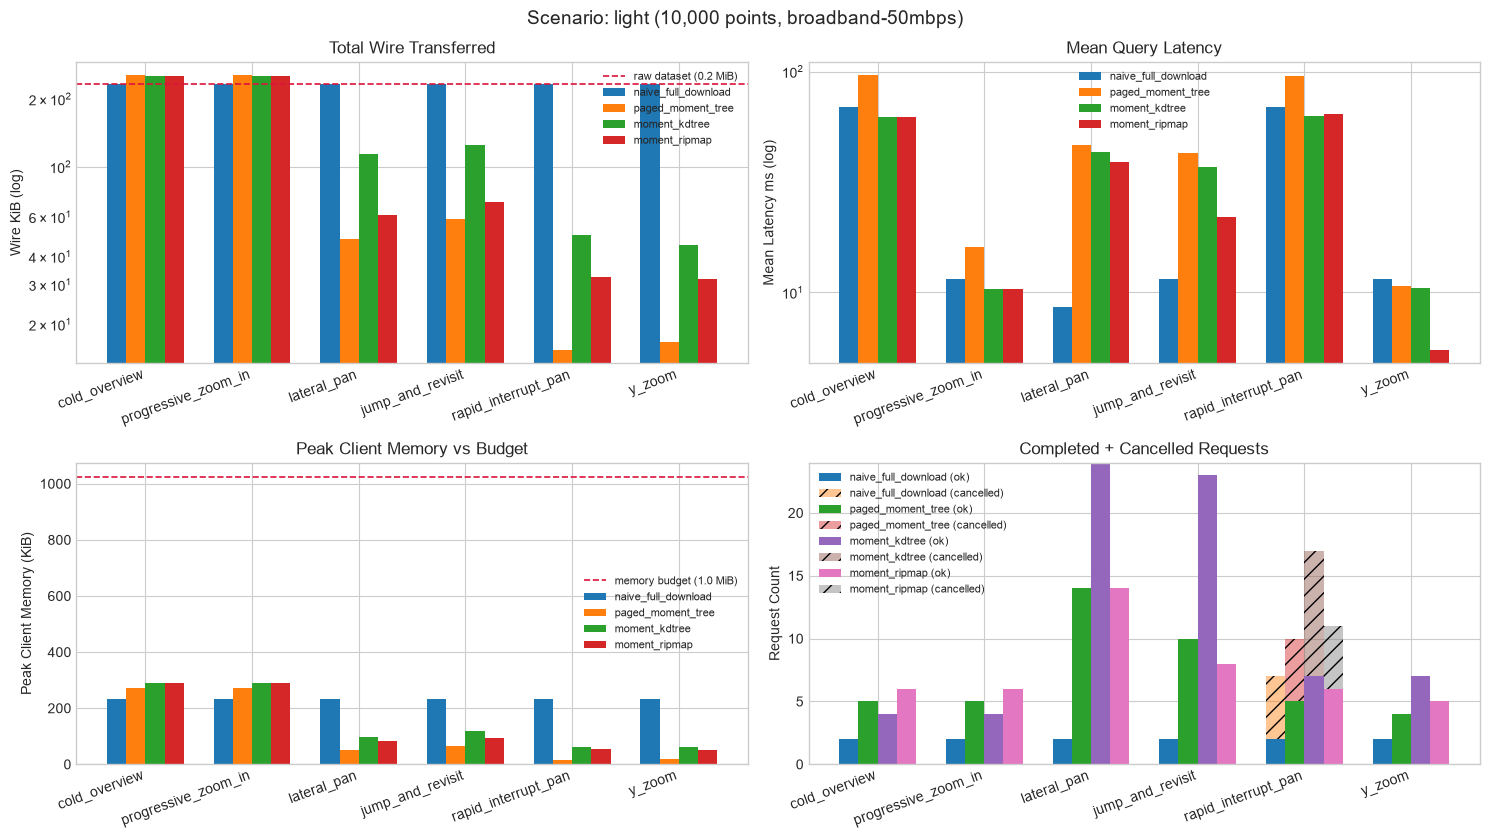

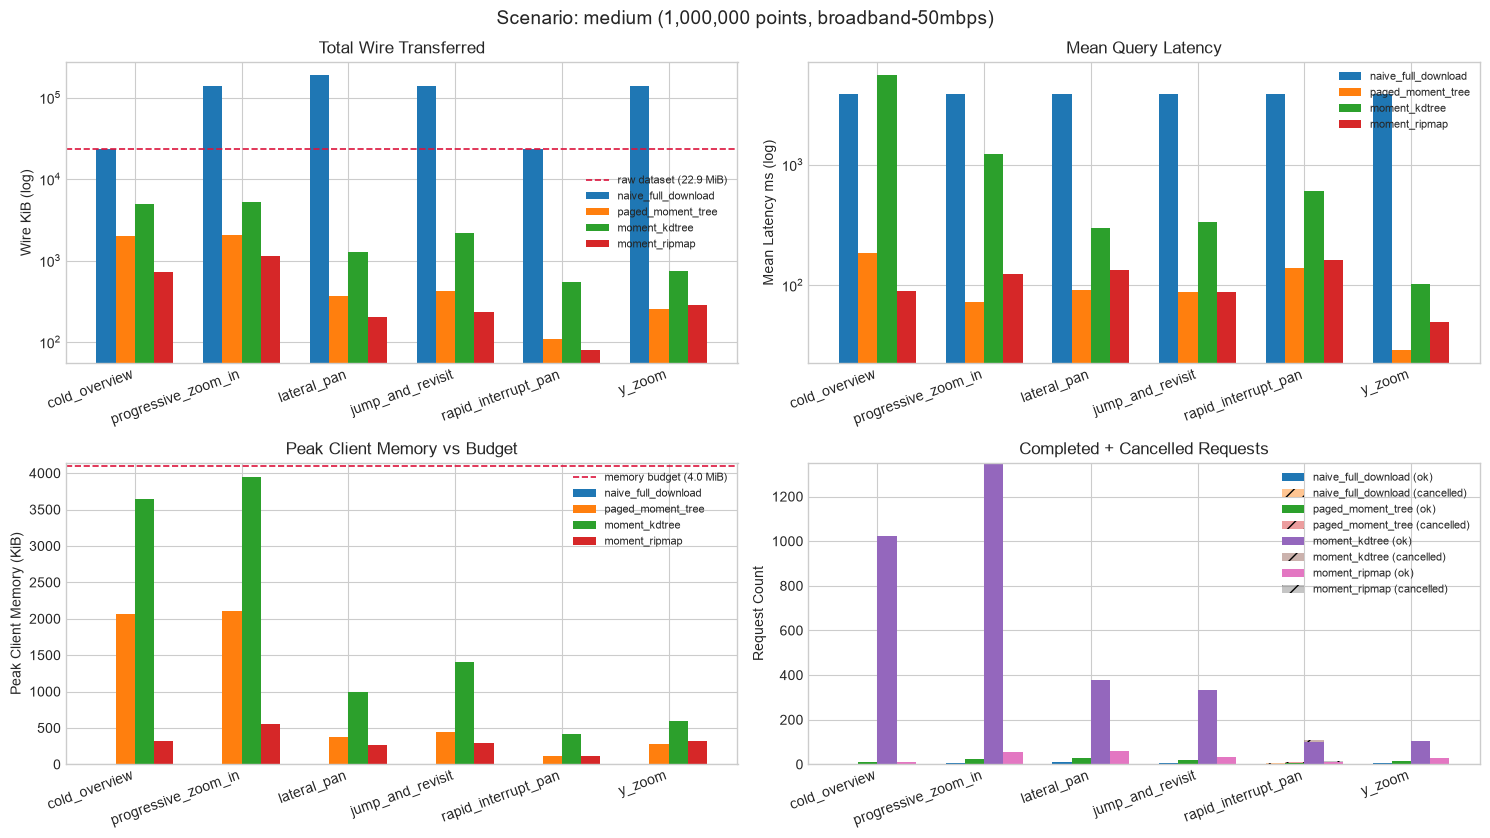

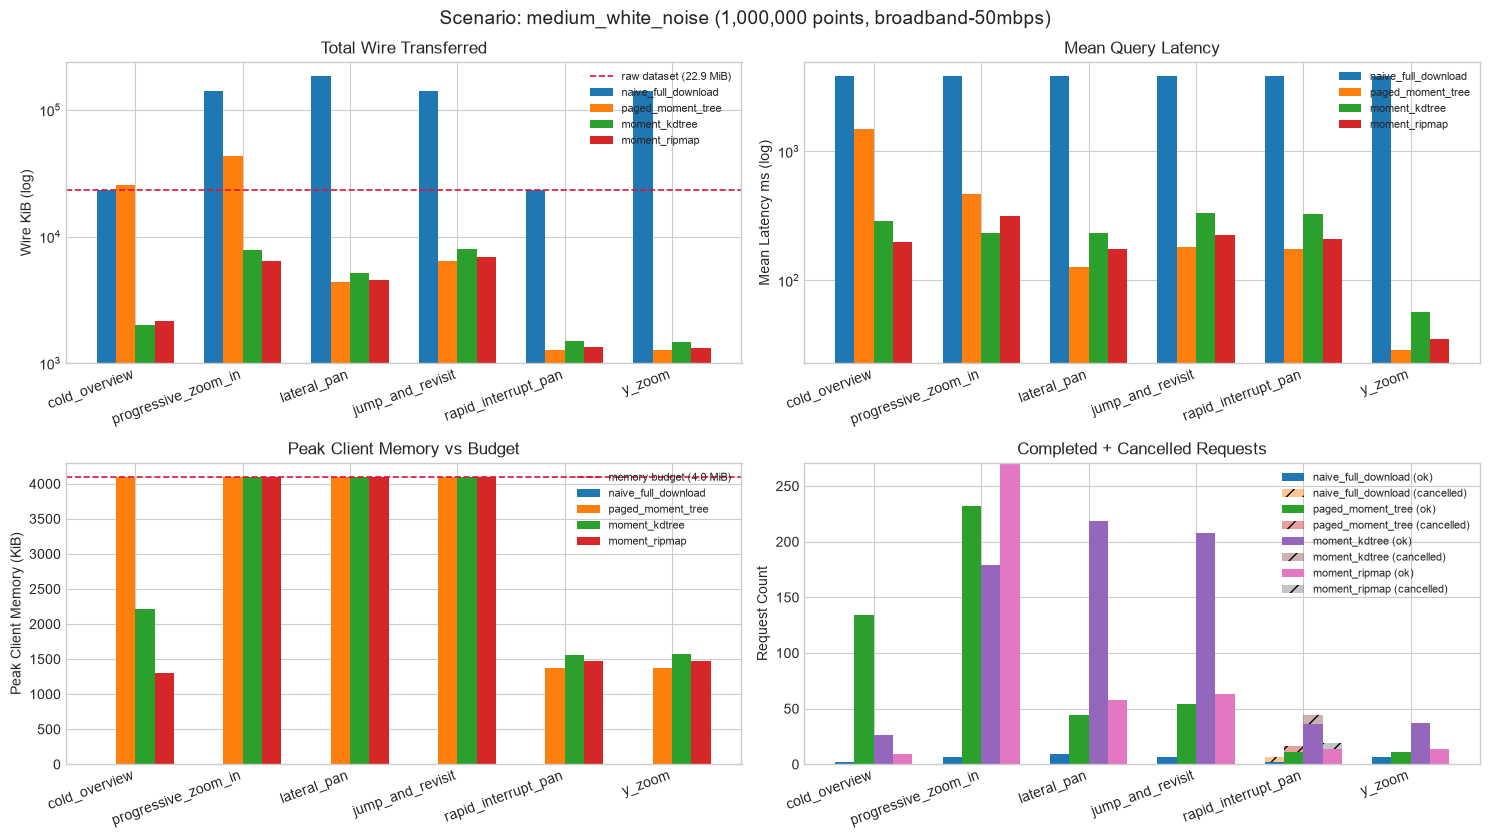

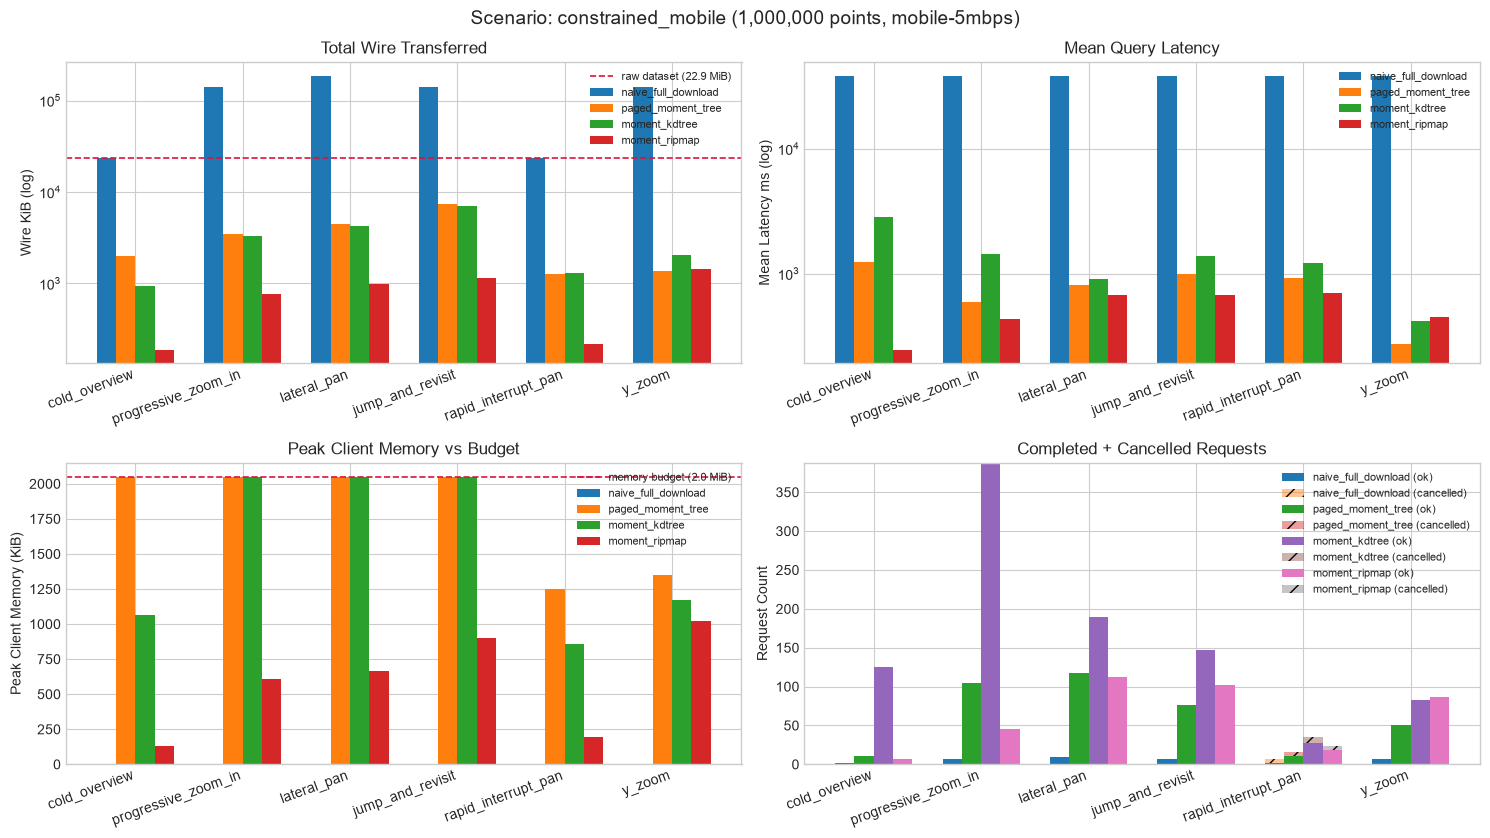

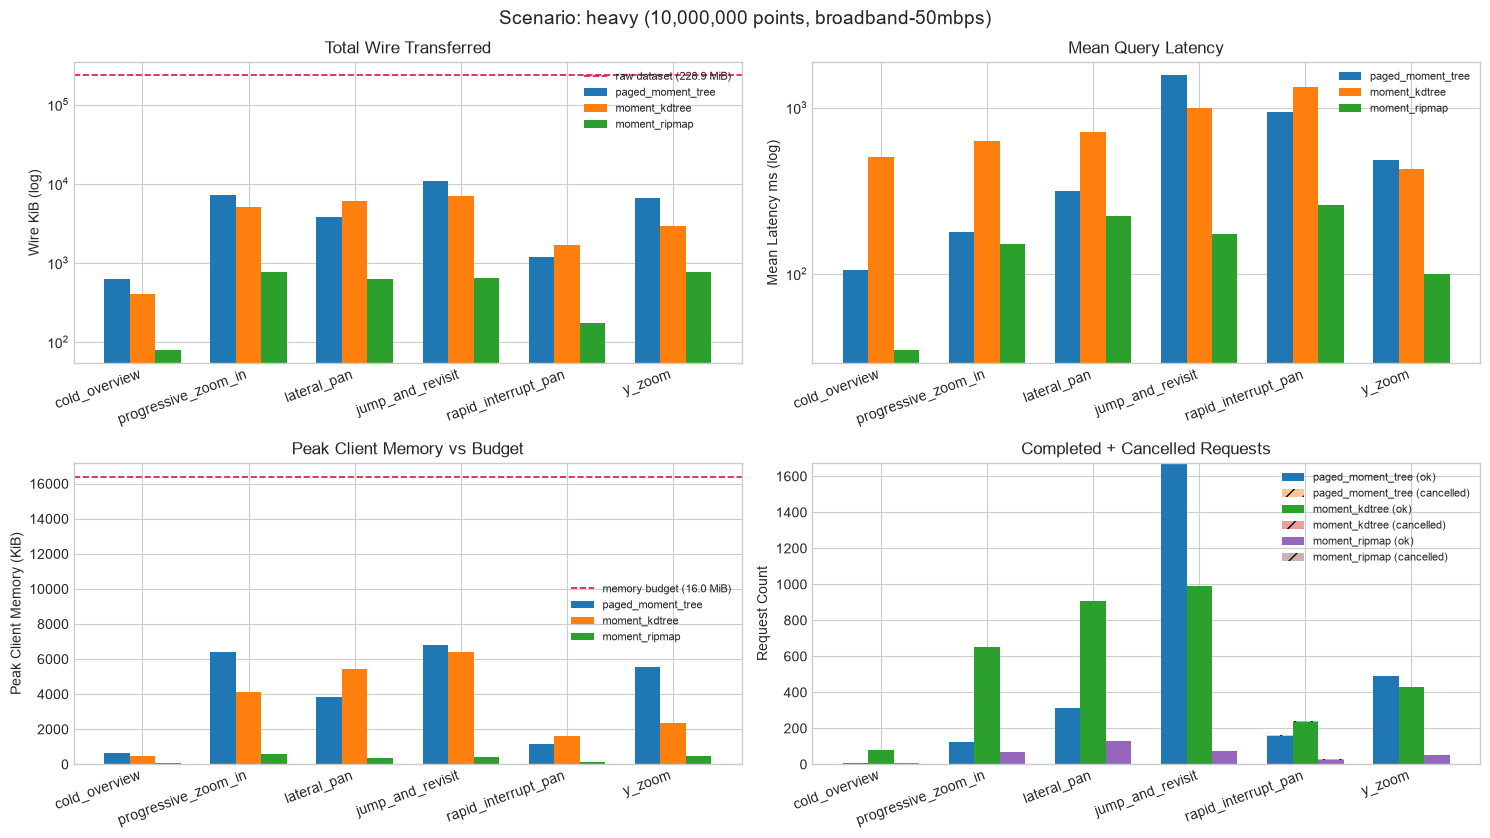

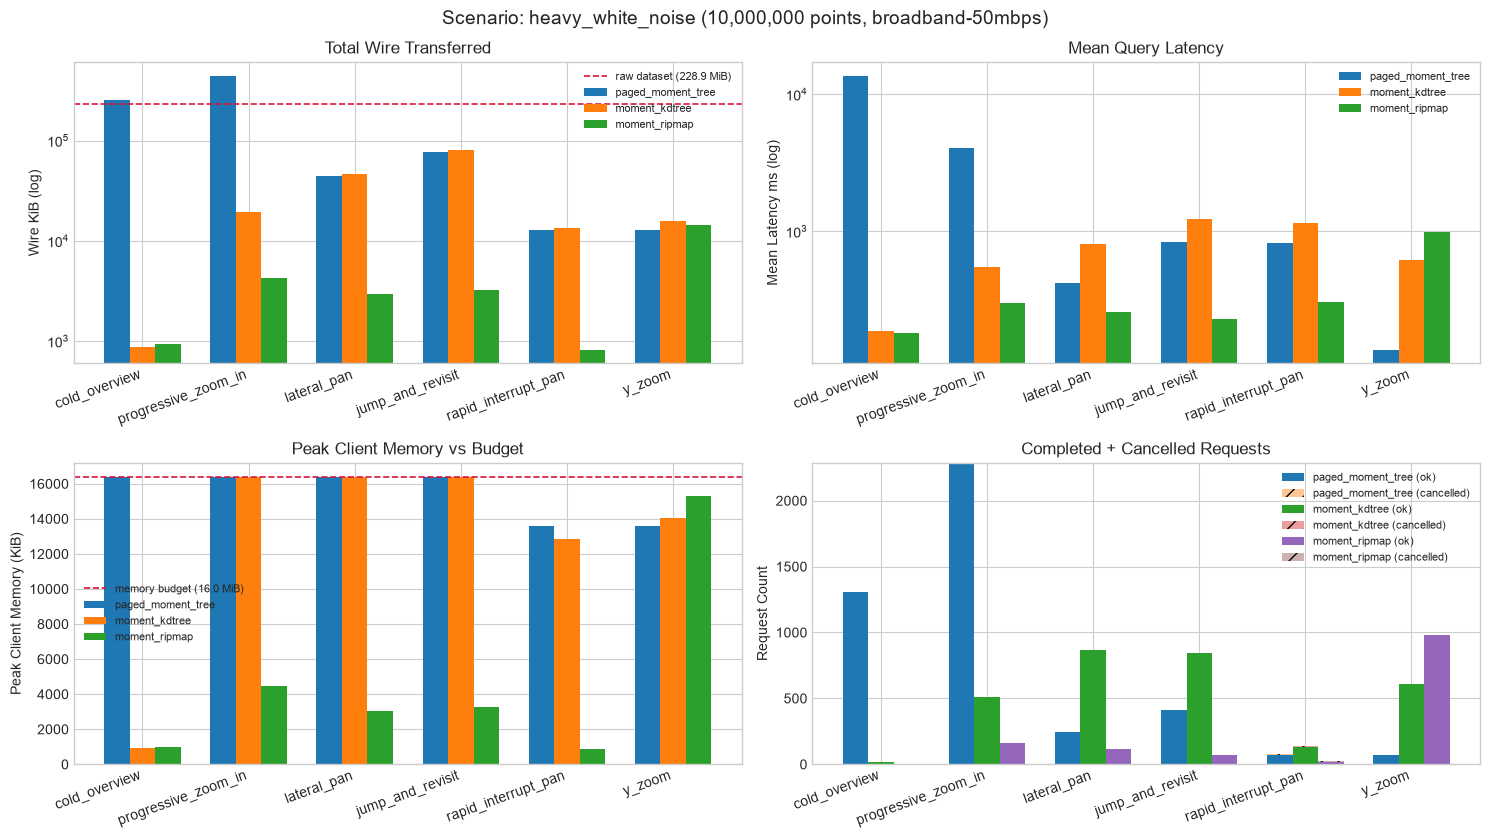

In [3]:
for scenario in SCENARIOS:
    sub = workloads_df[workloads_df["scenario"] == scenario]
    workloads = list(sub["workload"].unique())
    strategies = list(sub["strategy"].unique())
    x = np.arange(len(workloads))
    bar_w = 0.72 / max(len(strategies), 1)

    fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
    fig.suptitle(
        f"Scenario: {scenario} ({int(sub['points'].iloc[0]):,} points, {sub['network'].iloc[0]})",
        fontsize=14,
    )

    raw_kib = sub["raw_kib"].iloc[0]
    budget_kib = sub["budget_kib"].iloc[0]

    for i, strat in enumerate(strategies):
        s = sub[sub["strategy"] == strat].set_index("workload").reindex(workloads)
        offset = (i - (len(strategies) - 1) / 2.0) * bar_w

        axes[0, 0].bar(x + offset, s["wire_kib"], width=bar_w, label=strat)
        axes[0, 1].bar(x + offset, s["mean_latency_ms"], width=bar_w, label=strat)
        axes[1, 0].bar(x + offset, s["peak_mem_kib"], width=bar_w, label=strat)
        axes[1, 1].bar(x + offset, s["requests"], width=bar_w, label=f"{strat} (ok)")
        axes[1, 1].bar(
            x + offset,
            s["cancelled"],
            bottom=s["requests"],
            width=bar_w,
            alpha=0.45,
            hatch="//",
            label=f"{strat} (cancelled)",
        )

    axes[0, 0].axhline(
        raw_kib,
        color="crimson",
        linestyle="--",
        linewidth=1.2,
        label=f"raw dataset ({raw_kib / 1024:.1f} MiB)",
    )
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_ylabel("Wire KiB (log)")
    axes[0, 0].set_title("Total Wire Transferred")

    axes[0, 1].set_yscale("log")
    axes[0, 1].set_ylabel("Mean Latency ms (log)")
    axes[0, 1].set_title("Mean Query Latency")

    axes[1, 0].axhline(
        budget_kib,
        color="crimson",
        linestyle="--",
        linewidth=1.2,
        label=f"memory budget ({budget_kib / 1024:.1f} MiB)",
    )
    axes[1, 0].set_ylabel("Peak Client Memory (KiB)")
    axes[1, 0].set_title("Peak Client Memory vs Budget")

    axes[1, 1].set_ylabel("Request Count")
    axes[1, 1].set_title("Completed + Cancelled Requests")

    for ax in axes.flat:
        ax.set_xticks(x)
        ax.set_xticklabels(workloads, rotation=20, ha="right")
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

## 3. Step-by-Step Drill-Down (All Scenarios)
Inspects each interaction step per scenario to highlight overview cost, cache reuse during lateral panning, cache hits on revisit, and kernel counts.

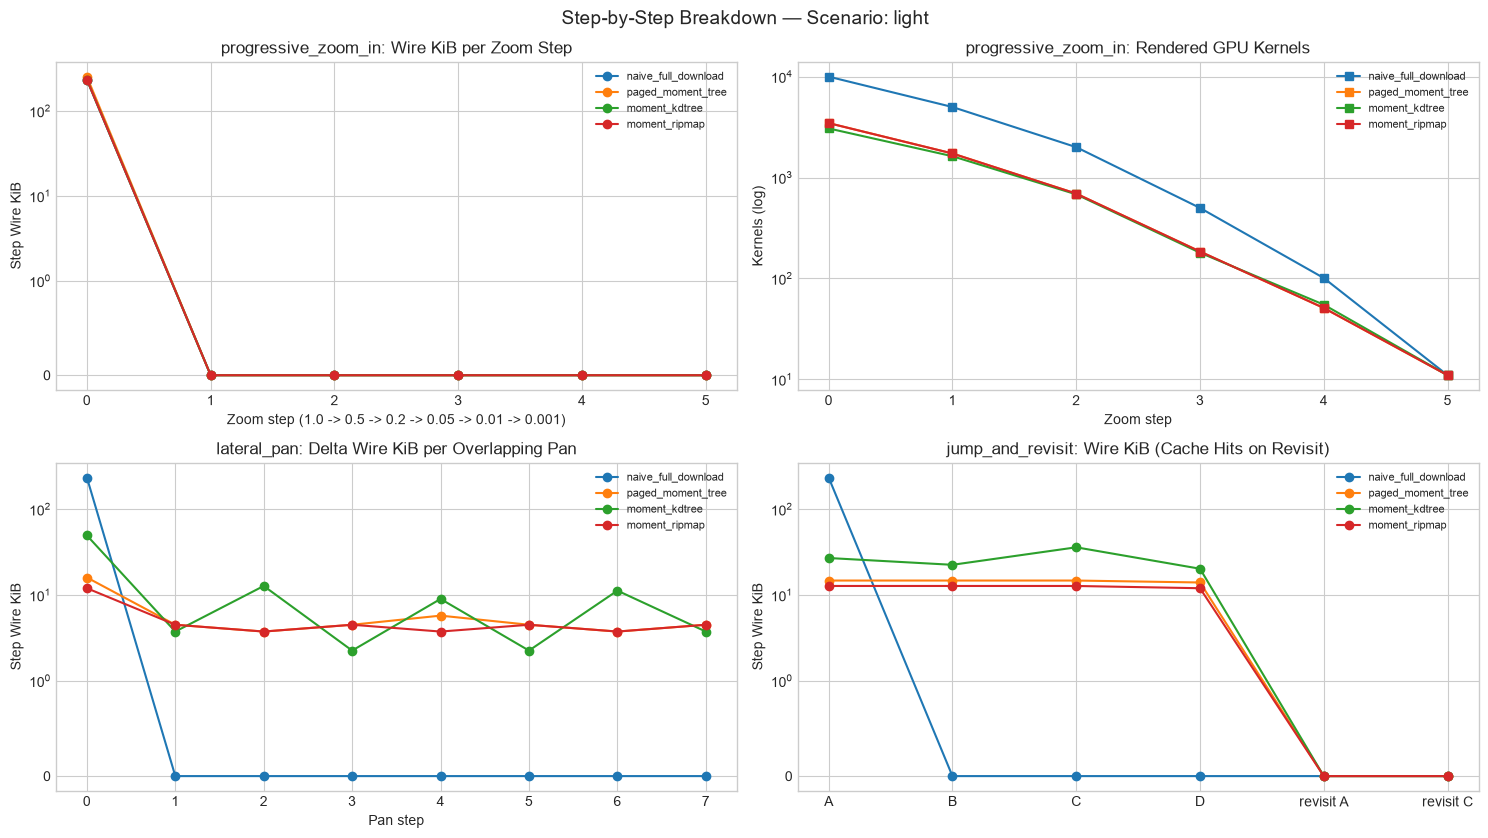

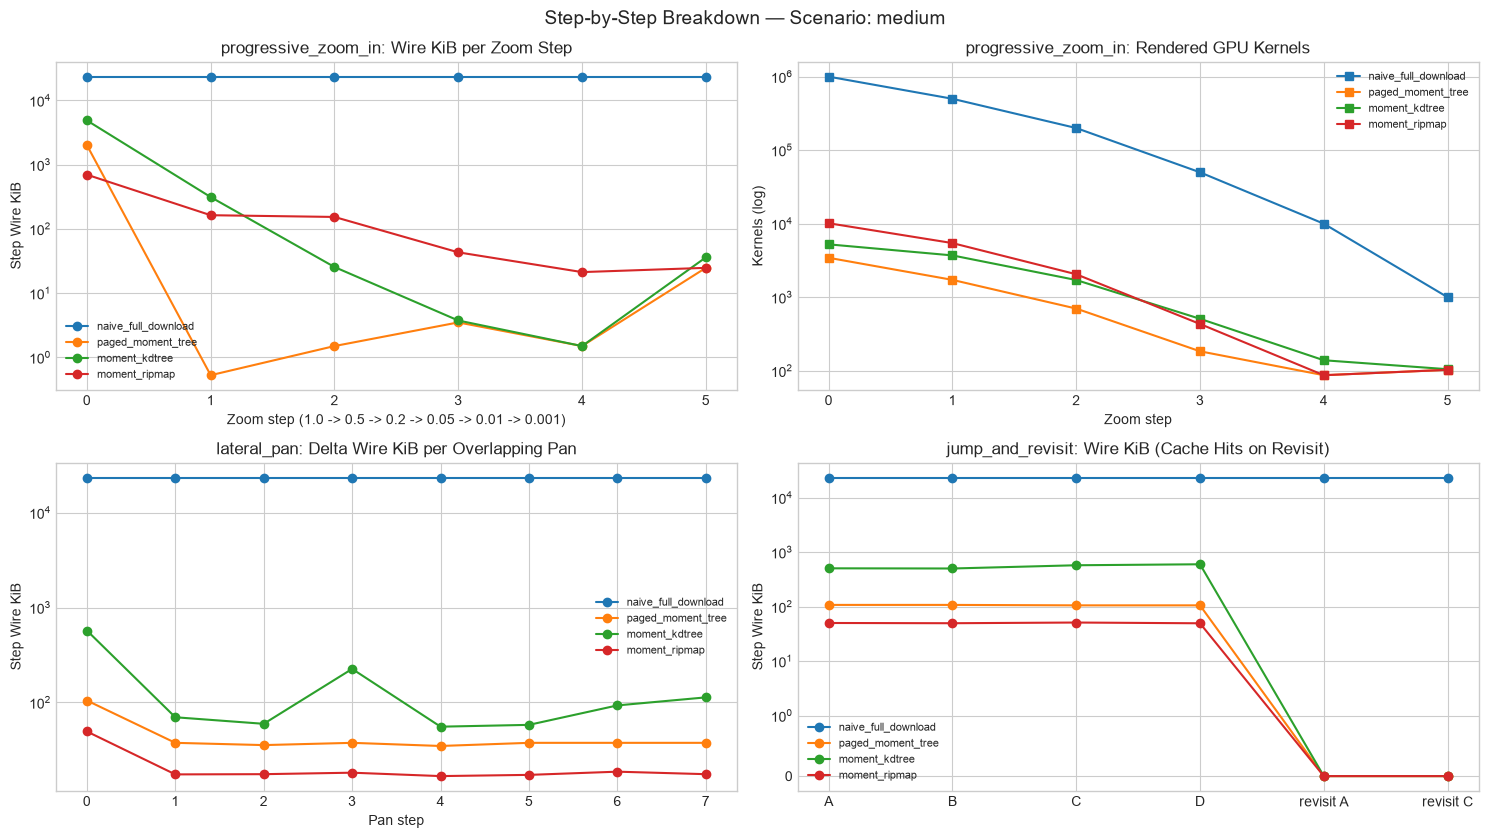

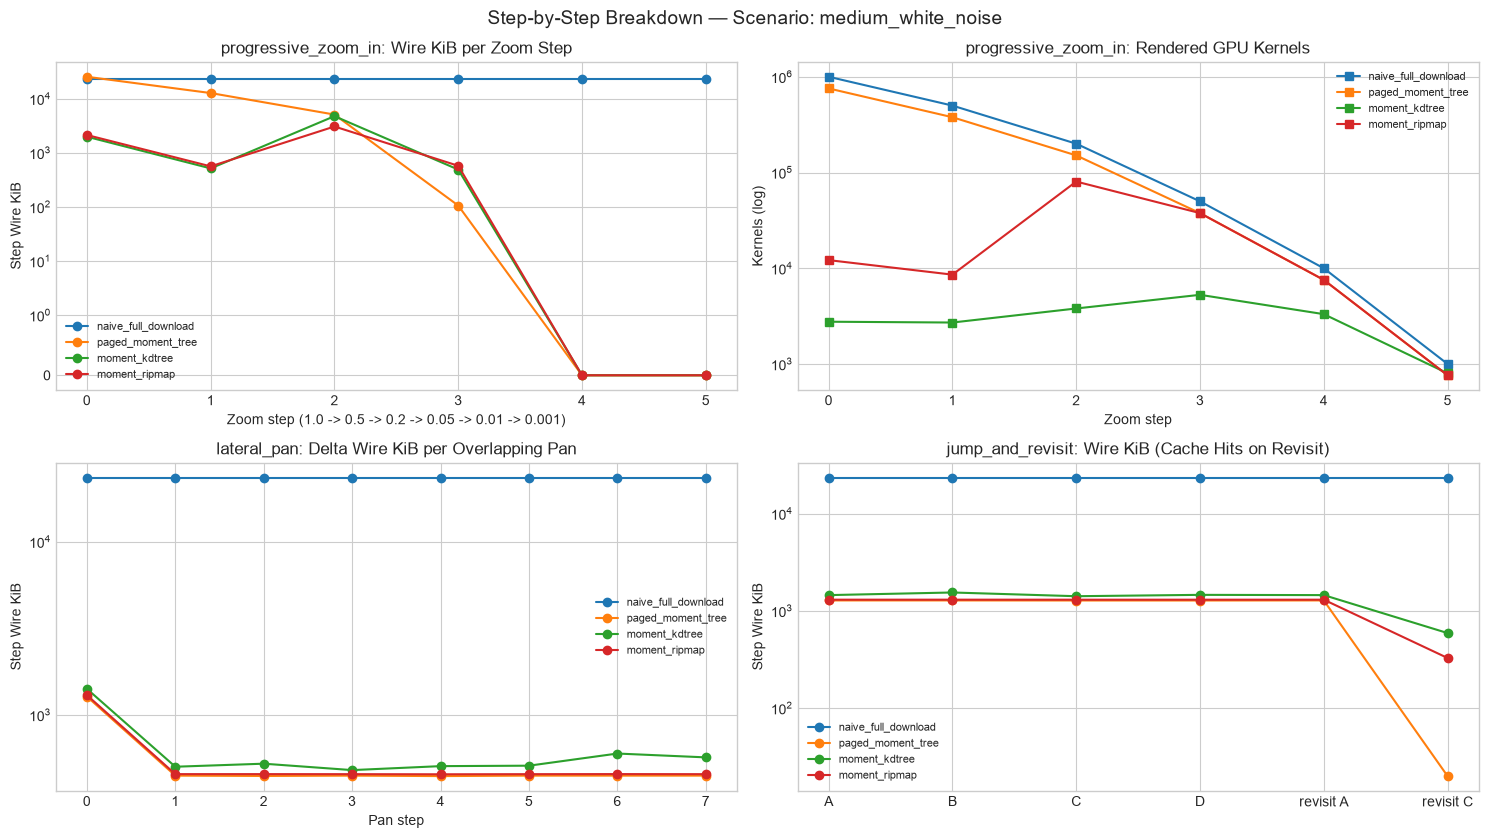

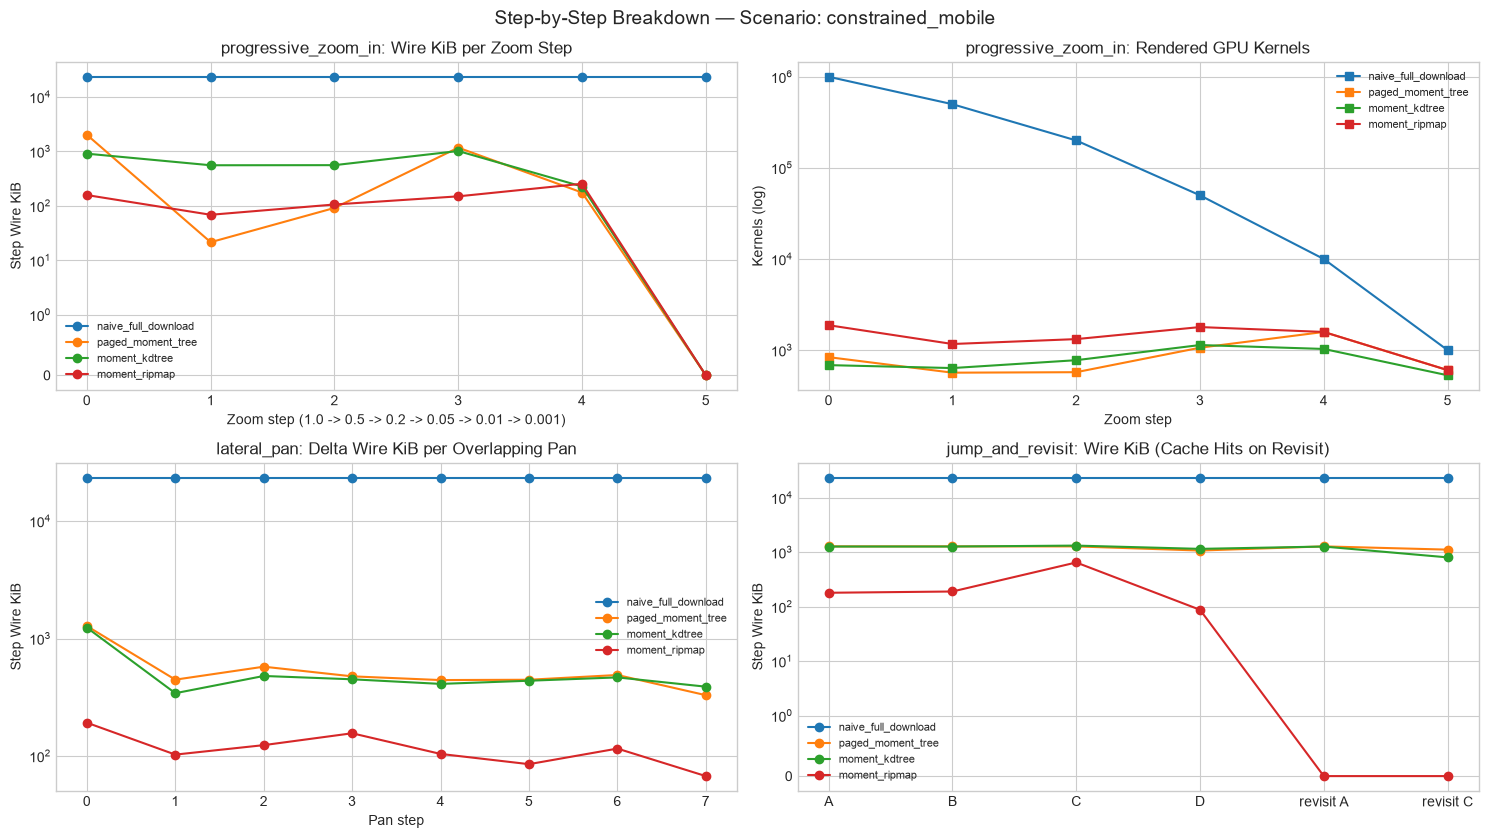

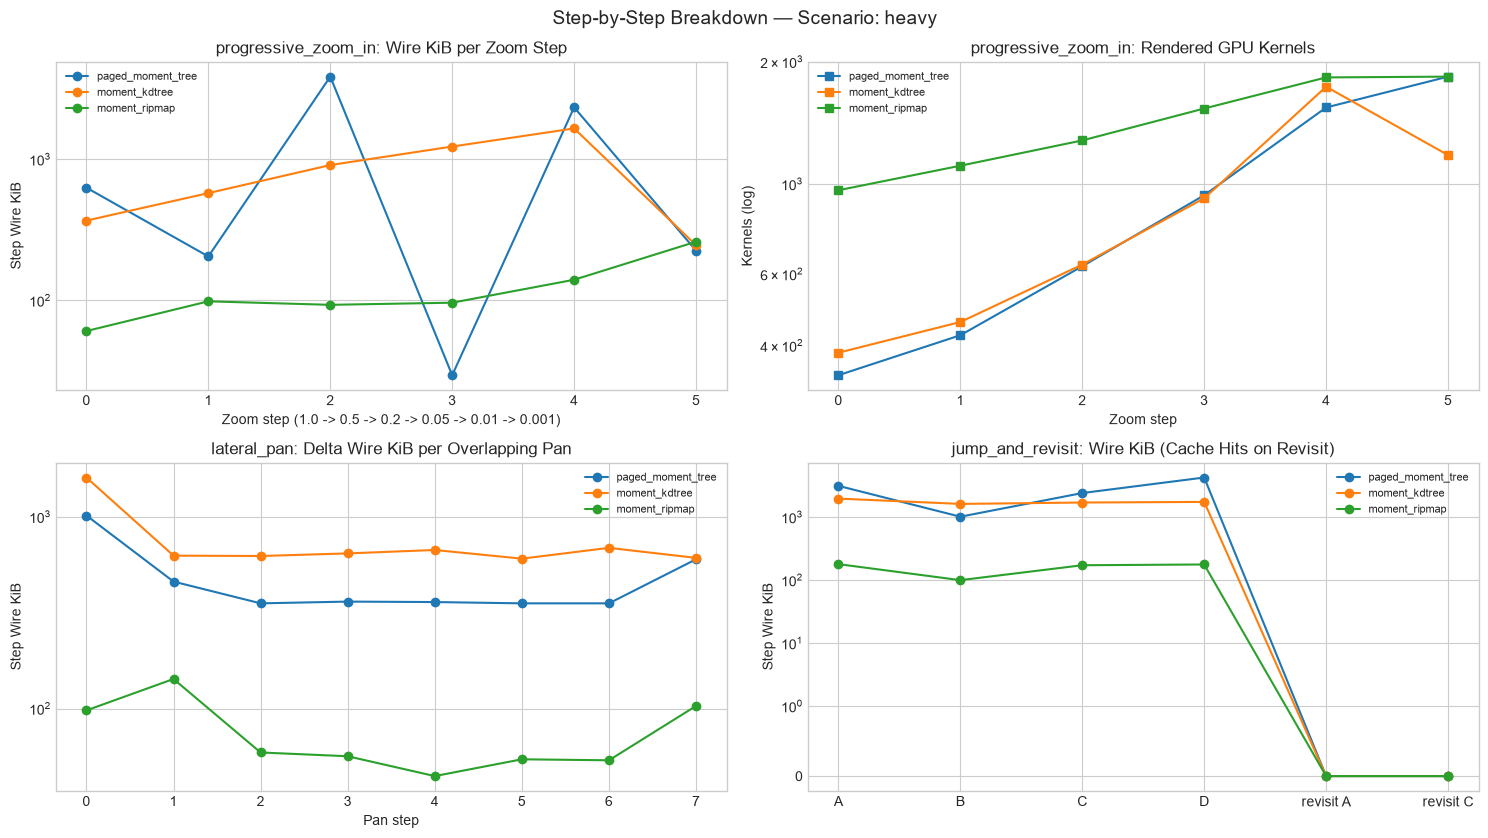

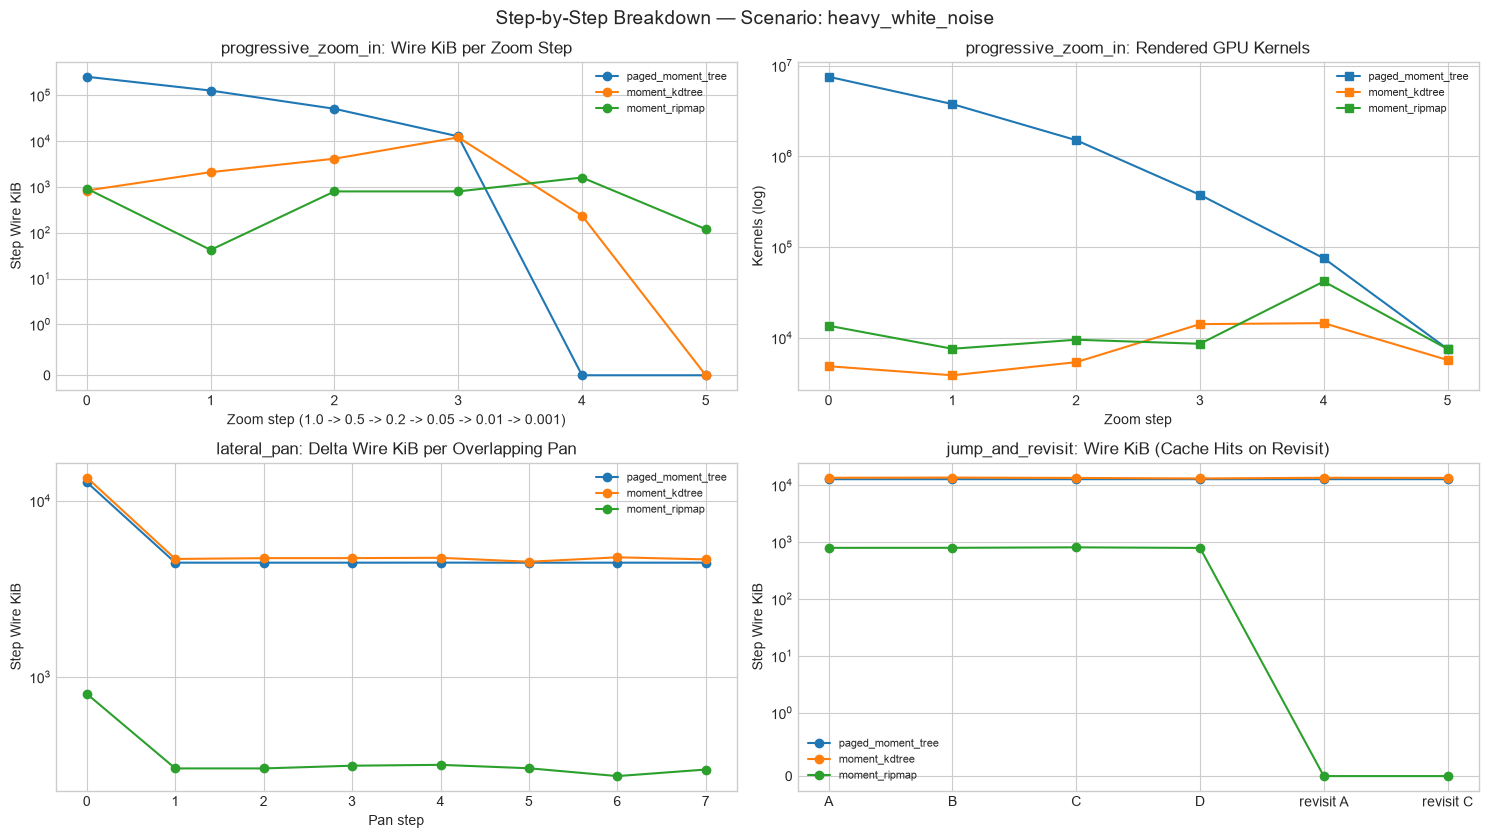

In [4]:
for scenario in SCENARIOS:
    sc_steps = steps_df[steps_df["scenario"] == scenario]
    strategies = list(sc_steps["strategy"].unique())

    fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
    fig.suptitle(f"Step-by-Step Breakdown — Scenario: {scenario}", fontsize=14)

    # 1. progressive_zoom_in: per-step wire KiB
    ax = axes[0, 0]
    zoom = sc_steps[sc_steps["workload"] == "progressive_zoom_in"]
    for strat in strategies:
        s = zoom[zoom["strategy"] == strat]
        ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_title("progressive_zoom_in: Wire KiB per Zoom Step")
    ax.set_xlabel("Zoom step (1.0 -> 0.5 -> 0.2 -> 0.05 -> 0.01 -> 0.001)")
    ax.set_ylabel("Step Wire KiB")
    ax.legend(fontsize=8)

    # 2. progressive_zoom_in: rendered kernel count per step
    ax = axes[0, 1]
    for strat in strategies:
        s = zoom[zoom["strategy"] == strat]
        ax.plot(s["step_idx"], s["kernel_count"], marker="s", label=strat)
    ax.set_yscale("log")
    ax.set_title("progressive_zoom_in: Rendered GPU Kernels")
    ax.set_xlabel("Zoom step")
    ax.set_ylabel("Kernels (log)")
    ax.legend(fontsize=8)

    # 3. lateral_pan: per-step wire KiB (shows cache reuse on overlapping pan)
    ax = axes[1, 0]
    pan = sc_steps[sc_steps["workload"] == "lateral_pan"]
    for strat in strategies:
        s = pan[pan["strategy"] == strat]
        ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_title("lateral_pan: Delta Wire KiB per Overlapping Pan")
    ax.set_xlabel("Pan step")
    ax.set_ylabel("Step Wire KiB")
    ax.legend(fontsize=8)

    # 4. jump_and_revisit: per-step wire KiB (revisit steps 4 & 5 show cache hits)
    ax = axes[1, 1]
    jump = sc_steps[sc_steps["workload"] == "jump_and_revisit"]
    for strat in strategies:
        s = jump[jump["strategy"] == strat]
        ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_xticks(range(6))
    ax.set_xticklabels(["A", "B", "C", "D", "revisit A", "revisit C"])
    ax.set_title("jump_and_revisit: Wire KiB (Cache Hits on Revisit)")
    ax.set_ylabel("Step Wire KiB")
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

## 4. Cross-Scenario Scaling
Shows total wire bytes as a **percentage of the raw dataset** and mean latency across all scenarios.

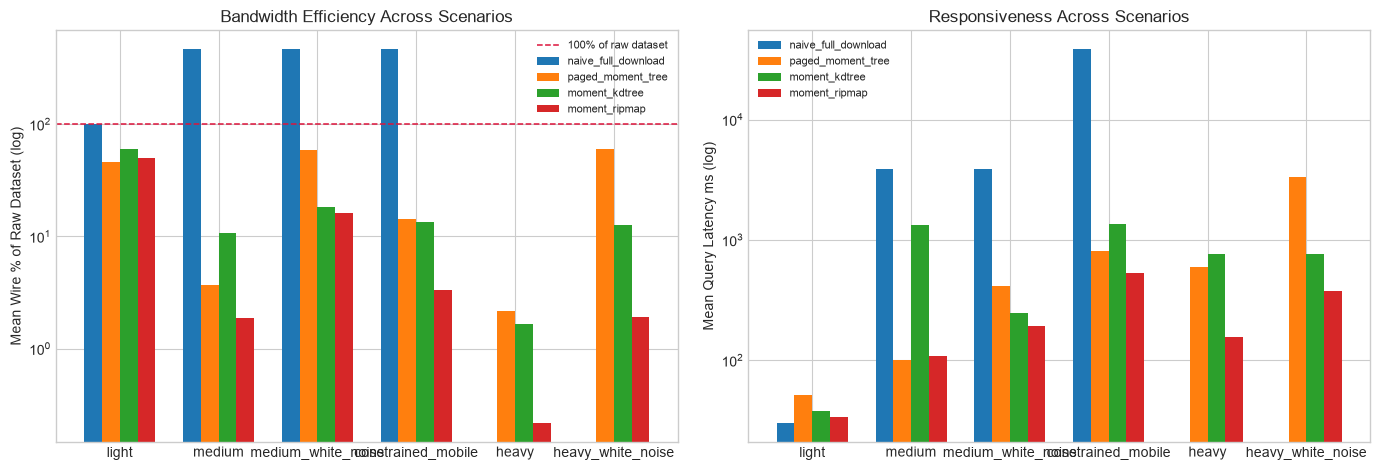

In [5]:
strategies = list(workloads_df["strategy"].unique())

agg = (
    workloads_df.groupby(["scenario", "strategy"], as_index=False)
    .agg(
        mean_wire_pct=("wire_pct_of_raw", "mean"),
        mean_latency_ms=("mean_latency_ms", "mean"),
        total_wire_mib=("wire_kib", lambda s: s.sum() / 1024.0),
    )
)

x = np.arange(len(SCENARIOS))
bar_w = 0.72 / max(len(strategies), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, strat in enumerate(strategies):
    s = agg[agg["strategy"] == strat].set_index("scenario").reindex(SCENARIOS)
    offset = (i - (len(strategies) - 1) / 2.0) * bar_w
    axes[0].bar(x + offset, s["mean_wire_pct"], width=bar_w, label=strat)
    axes[1].bar(x + offset, s["mean_latency_ms"], width=bar_w, label=strat)

axes[0].axhline(100.0, color="crimson", linestyle="--", linewidth=1.1, label="100% of raw dataset")
axes[0].set_yscale("log")
axes[0].set_ylabel("Mean Wire % of Raw Dataset (log)")
axes[0].set_title("Bandwidth Efficiency Across Scenarios")

axes[1].set_yscale("log")
axes[1].set_ylabel("Mean Query Latency ms (log)")
axes[1].set_title("Responsiveness Across Scenarios")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(SCENARIOS)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 5. Explicit Vertical Zoom (`y_zoom`)
Fixed 5% x-window: auto-y anchor → 2× → 8× → 32× box-zoom → 8× vertical pan → reset to auto-y.
2D strategies can cull cells far above/below the screen into single kernels; x-only partitions cannot (every x-block spans the full y-range).

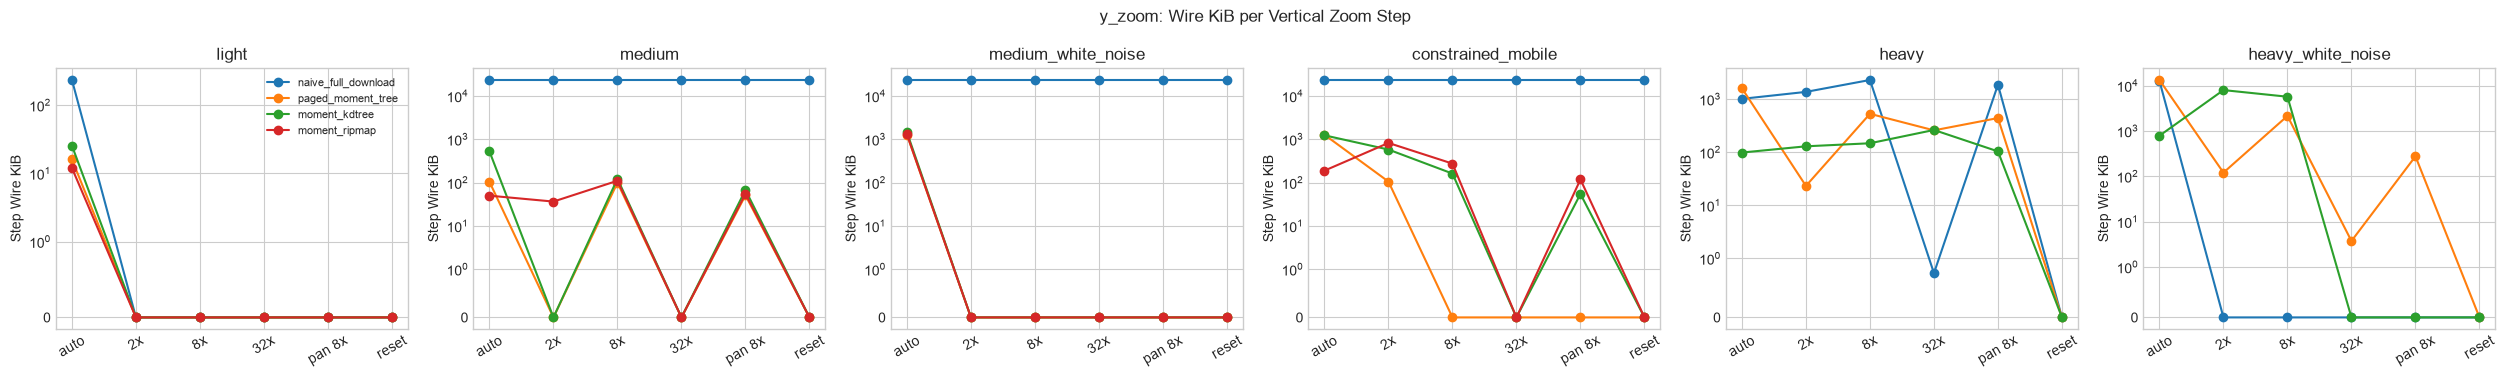

In [6]:
yz = steps_df[steps_df["workload"] == "y_zoom"]
if yz.empty:
    print("No y_zoom workload in these results.")
else:
    scen = [s for s in SCENARIOS if s in yz["scenario"].unique()]
    fig, axes = plt.subplots(1, len(scen), figsize=(4.2 * len(scen), 3.8), squeeze=False)
    for ax, scenario in zip(axes[0], scen):
        sub = yz[yz["scenario"] == scenario]
        for strat in sub["strategy"].unique():
            s = sub[sub["strategy"] == strat]
            ax.plot(s["step_idx"], s["wire_kib"], marker="o", label=strat)
        ax.set_yscale("symlog", linthresh=1.0)
        ax.set_xticks(range(6))
        ax.set_xticklabels(["auto", "2x", "8x", "32x", "pan 8x", "reset"], rotation=30)
        ax.set_title(scenario)
        ax.set_ylabel("Step Wire KiB")
    axes[0][0].legend(fontsize=8)
    fig.suptitle("y_zoom: Wire KiB per Vertical Zoom Step")
    plt.tight_layout()
    plt.show()

## 6. Strategy Head-to-Head: Storage Cost vs Transfer
Static storage overhead (vs raw 24 B/point) against total wire per workload, per scenario. The 1D x-tree is cheapest to store but collapses on vertically incoherent data; the k-d tree keeps raw-level storage; the ripmap trades ~2× storage for few, large plane reads.

In [7]:
storage = (
    workloads_df.groupby(["scenario", "strategy"], as_index=False)
    .agg(storage_mib=("storage_kib", lambda s: s.iloc[0] / 1024.0),
         storage_overhead_pct=("storage_overhead_pct", "first"),
         build_ms=("build_ms", "first"),
         total_wire_mib=("wire_kib", lambda s: s.sum() / 1024.0),
         total_requests=("requests", "sum"),
         mean_latency_ms=("mean_latency_ms", "mean"))
)
display(storage.round(1))

pivot = workloads_df.pivot_table(index=["scenario", "workload"], columns="strategy", values="wire_kib")
display((pivot / 1024.0).round(2).rename_axis(columns="wire MiB by strategy"))
lat = workloads_df.pivot_table(index=["scenario", "workload"], columns="strategy", values="mean_latency_ms")
display(lat.round(0).rename_axis(columns="mean latency ms by strategy"))

,scenario,strategy,storage_mib,storage_overhead_pct,build_ms,total_wire_mib,total_requests,mean_latency_ms
0,constrained_mobile,moment_kdtree,25.1,9.5,250.5,18.5,961,1364.1
1,constrained_mobile,moment_ripmap,35.0,52.8,197.0,4.6,371,528.0
2,constrained_mobile,naive_full_download,22.9,0.0,101.8,640.9,34,38501.0
3,constrained_mobile,paged_moment_tree,24.9,8.6,122.6,19.5,370,806.4
4,heavy,moment_kdtree,250.7,9.5,2777.4,22.6,3300,766.0
5,heavy,moment_ripmap,407.0,77.8,2435.1,3.0,354,157.0
6,heavy,paged_moment_tree,248.6,8.6,1239.5,29.6,2766,598.5
7,heavy_white_noise,moment_kdtree,250.7,9.5,2322.2,172.5,2976,759.0
8,heavy_white_noise,moment_ripmap,407.0,77.8,1876.9,26.1,1356,377.3
9,heavy_white_noise,paged_moment_tree,248.6,8.6,696.4,825.9,4391,3324.1


wire MiB by strategy                    moment_kdtree  moment_ripmap  naive_full_download  paged_moment_tree
scenario           workload                                                                                 
constrained_mobile cold_overview                 0.92           0.18                22.89               1.97
                   jump_and_revisit              6.95           1.11               137.33               7.13
                   lateral_pan                   4.14           0.95               183.11               4.38
                   progressive_zoom_in           3.22           0.75               137.33               3.39
                   rapid_interrupt_pan           1.27           0.21                22.89               1.25
                   y_zoom                        2.02           1.41               137.33               1.35
heavy              cold_overview                 0.40           0.08                  NaN               0.62
                   jump_and_revisit              6.89           0.63                  NaN              10.53
                   lateral_pan                   5.96           0.62                  NaN               3.76
                   progressive_zoom_in           4.90           0.75                  NaN               7.10
                   rapid_interrupt_pan           1.66           0.17                  NaN               1.17
                   y_zoom                        2.83           0.74                  NaN               6.41
heavy_white_noise  cold_overview                 0.85           0.92                  NaN             248.57
                   jump_and_revisit             78.62           3.13                  NaN              74.60
                   lateral_pan                  45.30           2.87                  NaN              42.89
                   progressive_zoom_in          19.00           4.21                  NaN             435.02
                   rapid_interrupt_pan          13.20           0.80                  NaN              12.44
                   y_zoom                       15.57          14.16                  NaN              12.44
light              cold_overview                 0.25           0.25                 0.23               0.25
                   jump_and_revisit              0.12           0.07                 0.23               0.06
                   lateral_pan                   0.11           0.06                 0.23               0.05
                   progressive_zoom_in           0.25           0.25                 0.23               0.25
                   rapid_interrupt_pan           0.05           0.03                 0.23               0.02
                   y_zoom                        0.04           0.03                 0.23               0.02
medium             cold_overview                 4.79           0.71                22.89               1.97
                   jump_and_revisit              2.16           0.23               137.33               0.42
                   lateral_pan                   1.25           0.20               183.11               0.36
                   progressive_zoom_in           5.16           1.11               137.33               2.00
                   rapid_interrupt_pan           0.53           0.08                22.89               0.10
                   y_zoom                        0.73           0.28               137.33               0.25
medium_white_noise cold_overview                 1.97           2.12                22.89              24.86
                   jump_and_revisit              7.75           6.71               137.33               6.26
                   lateral_pan                   5.01           4.41               183.11               4.29
                   progressive_zoom_in           7.60           6.22               137.33              42.37
                   rapid_interrupt_pan           1.45           1.30        

mean latency ms by strategy             moment_kdtree  moment_ripmap  naive_full_download  paged_moment_tree
scenario           workload                                                                                 
constrained_mobile cold_overview               2830.0          246.0              38501.0             1241.0
                   jump_and_revisit            1382.0          672.0              38501.0              999.0
                   lateral_pan                  912.0          673.0              38501.0              809.0
                   progressive_zoom_in         1427.0          434.0              38501.0              594.0
                   rapid_interrupt_pan         1211.0          697.0              38501.0              921.0
                   y_zoom                       422.0          447.0              38501.0              274.0
heavy              cold_overview                506.0           35.0                  NaN              106.0
                   jump_and_revisit             992.0          175.0                  NaN             1562.0
                   lateral_pan                  713.0          222.0                  NaN              315.0
                   progressive_zoom_in          627.0          151.0                  NaN              179.0
                   rapid_interrupt_pan         1331.0          258.0                  NaN              947.0
                   y_zoom                       427.0          100.0                  NaN              483.0
heavy_white_noise  cold_overview                188.0          181.0                  NaN            13690.0
                   jump_and_revisit            1230.0          231.0                  NaN              831.0
                   lateral_pan                  803.0          257.0                  NaN              419.0
                   progressive_zoom_in          553.0          299.0                  NaN             4047.0
                   rapid_interrupt_pan         1159.0          307.0                  NaN              821.0
                   y_zoom                       622.0          990.0                  NaN              137.0
light              cold_overview                 62.0           62.0                 69.0               96.0
                   jump_and_revisit              37.0           22.0                 12.0               43.0
                   lateral_pan                   43.0           39.0                  9.0               47.0
                   progressive_zoom_in           10.0           10.0                 12.0               16.0
                   rapid_interrupt_pan           63.0           64.0                 69.0               95.0
                   y_zoom                        10.0            6.0                 12.0               11.0
medium             cold_overview               5502.0           90.0               3871.0              185.0
                   jump_and_revisit             336.0           88.0               3871.0               88.0
                   lateral_pan                  299.0          134.0               3871.0               92.0
                   progressive_zoom_in         1218.0          123.0               3871.0               73.0
                   rapid_interrupt_pan          600.0          162.0               3871.0              140.0
                   y_zoom                       102.0           50.0               3871.0               29.0
medium_white_noise cold_overview                288.0          198.0               3871.0             1487.0
                   jump_and_revisit             331.0          225.0               3871.0              182.0
                   lateral_pan                  232.0          175.0               3871.0              127.0
                   progressive_zoom_in          232.0          314.0               3871.0              464.0
                   rapid_interrupt_pan          329.0          210.0        